#### Configuration
Compare fixed-push predictions and nominal-state Jacobians on saved plain-A-LQR generations.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'llm' / 'model.py').is_file())
sys.path.insert(0, str(REPO_ROOT))
RUN = False
MODEL_NAME, CONCEPT, PROMPT = 'Qwen/Qwen3-4B', 'football', 'Once upon a time'
Q, R, QF, LAMBDA = 0.1, 10, 0.1, 4
SCALES, R_VALUES = (0.01, 0.1, 0.3, 1.0), (10, 100, 1000)
NUM_PROMPTS, TRIALS, GENERATION_SEED = 100, 20, 2
PREDICTORS = ('identity', 'mean_jacobian', 'steering_dmd', 'prompt_jacobian')
LABELS = dict(zip(PREDICTORS, ('Identity', 'Mean Jacobian', 'Steering DMD', 'Per-prompt Jacobian')))
BASE = REPO_ROOT / 'artifacts' / MODEL_NAME.rsplit('/', 1)[-1].lower()
RUN_DIR = BASE / '04_linear_prediction'
E_PATH = BASE / '01_concept_direction_steering' / f'E_{CONCEPT}_n200_seed0.pt'
A_PATH = BASE / '02_qwen3_model_ablation' / f'A_{CONCEPT}_n50_ctx32_seed0.pt'
DMD_PATH = RUN_DIR / f'steering_dmd_{CONCEPT}.pt'
FIRST_PATH, GENERATION_PATH = RUN_DIR / 'first_token.csv', RUN_DIR / 'generation.csv'


#### Model and caches
Load FP32 weights and the unchanged direction, Mean Jacobian and steering-DMD cache only when recomputing.


In [2]:
if RUN:
    import torch
    from transformers import AutoModelForCausalLM
    from llm.model import load_model
    from llm.linear_prediction import steering_dmd, first_token, grade

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_float32_matmul_precision('highest')
    tokenizer, model = load_model(MODEL_NAME, dtype=torch.float32)
    model.requires_grad_(False)
    E = torch.load(E_PATH, map_location='cpu', weights_only=True)
    A_jac = torch.load(A_PATH, map_location='cpu', weights_only=True)
    dmd = steering_dmd(DMD_PATH, model, tokenizer, E, CONCEPT, Q, R, QF)


#### First token: push size
Reuse the 100 held-out prompts, every block, Identity gains and fixed lambda-4 pushes; JVPs are at unsteered states.


In [3]:
if RUN:
    dmd['config']['test_prompts'] = dmd['config']['test_prompts'][:NUM_PROMPTS]
    first = first_token(model, E, A_jac, dmd, scales=SCALES, q=Q, r=R, qf=QF, strength=LAMBDA)
    first.to_csv(FIRST_PATH, index=False)
else:
    first = pd.read_csv(FIRST_PATH)
first = first.loc[first.scale.isin(SCALES) & first.predictor.isin(PREDICTORS)]
summary = first.groupby(['scale', 'predictor']).agg(
    rel_dev=('rel_dev', 'median'), err_perp=('err_perp', 'median'),
    low=('err_perp', lambda x: x.quantile(0.25)), high=('err_perp', lambda x: x.quantile(0.75)),
    n=('err_perp', 'size')).reset_index()
display(summary.pivot(index=['scale', 'rel_dev'], columns='predictor', values='err_perp')
        .rename(columns=LABELS).round(5))


,predictor,Identity,Mean Jacobian,Per-prompt Jacobian,Steering DMD
scale,rel_dev,,,,
0.01,0.003531,1.02041,0.90249,0.00487,0.82604
0.10,0.035785,1.02031,0.90546,0.04925,0.82795
0.30,0.111373,1.01993,0.89058,0.15428,0.82964
1.00,0.404780,1.02585,0.84713,0.56122,0.81323


#### Prediction versus deviation
Plot median final-state rollout off-concept error with the interquartile range across prompts.


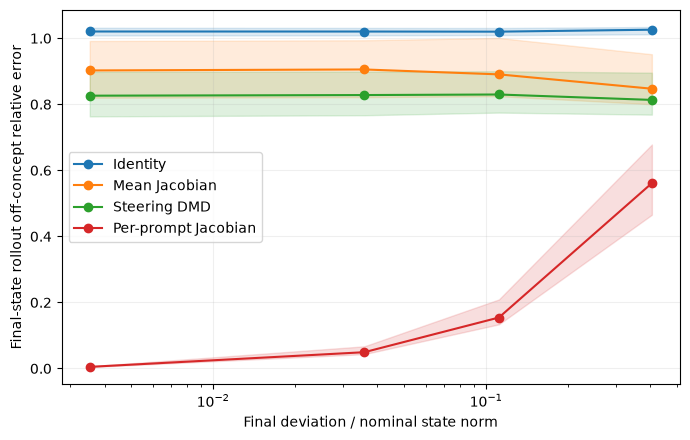

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in PREDICTORS:
    curve = summary.loc[summary.predictor.eq(name)].sort_values('rel_dev')
    line, = ax.plot(curve.rel_dev, curve.err_perp, 'o-', label=LABELS[name])
    ax.fill_between(curve.rel_dev, curve.low, curve.high, color=line.get_color(), alpha=0.15)
ax.set(xscale='log', xlabel='Final deviation / nominal state norm',
       ylabel='Final-state rollout off-concept relative error')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'prediction_vs_deviation.png', dpi=150)
plt.show()


#### First token versus later tokens
Replay 20 saved plain-A-LQR completions per R; compare nominal-state JVPs with Mean-Jacobian predictions on the same pushes.


In [5]:
generation = pd.read_csv(GENERATION_PATH)
plain = generation.loc[generation.controller.eq('none') & generation.R.isin(R_VALUES)
                       & generation['lambda'].eq(LAMBDA) & generation.seed.eq(GENERATION_SEED)]
plain = plain.groupby('R', group_keys=False).head(TRIALS)
if RUN:
    nominal = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, dtype=torch.float32, device_map=str(model.device),
        attn_implementation=model.config._attn_implementation).eval().requires_grad_(False)
    plain = grade(model, nominal, E, A_jac, plain, len(tokenizer(PROMPT)['input_ids']), Q, QF, LAMBDA)
    generation = pd.concat([plain, generation.loc[generation.controller.eq('pred_local')]], ignore_index=True)
    generation.to_csv(GENERATION_PATH, index=False)
    del nominal, model
    torch.cuda.empty_cache()


#### Generation summary
Earlier columns are the distinct w=2, steered-state-Jacobian experiment; current columns use plain A-LQR and nominal-state Jacobians.


In [6]:
rows = []
for r, block in plain.groupby('R'):
    earlier = generation.loc[generation.controller.eq('pred_local') & generation.R.eq(r)]
    for predictor, reference in [('prompt_jacobian', 'local_jacobian'), ('mean_jacobian', 'mean_jacobian')]:
        rows.append(dict(R=r, predictor=LABELS[predictor], n=len(block),
                         first_token=block[f'{predictor}_error_step0'].mean(),
                         later_tokens=block[f'{predictor}_error_later'].mean(),
                         earlier_first=earlier[f'{reference}_error_step0'].mean(),
                         earlier_later=earlier[f'{reference}_error_later'].mean()))
display(pd.DataFrame(rows).round(5))


,R,predictor,n,first_token,later_tokens,earlier_first,earlier_later
0,10,Per-prompt Jacobian,20,0.56975,0.83006,0.82675,0.81735
1,10,Mean Jacobian,20,1.05285,0.87804,1.24214,0.92333
2,100,Per-prompt Jacobian,20,0.11294,0.67489,0.11670,0.65267
3,100,Mean Jacobian,20,1.10487,0.89526,1.14433,0.89306
4,1000,Per-prompt Jacobian,20,0.01287,0.61773,0.01284,0.61597
5,1000,Mean Jacobian,20,1.08241,0.89326,1.08689,0.89301


#### Result
Per-prompt rollout error rises from 0.00487 at scale 0.01 to 0.561 at scale 1; the shared predictors remain inaccurate even at scale 0.01 (0.826–1.020). At R=1000, nominal-state prediction on plain A-LQR gives 0.01287 first-token error and 0.61773 later-token error, versus 0.01284 and 0.61597 in the earlier steered-state cancellation run.
